# PathSnap: Phase 1 model comparison

This notebook shows how the model-comparison results and figures are produced.

**Pipeline:** `src/models/train_models.py` trains each model with 5-fold trip-grouped cross-validation on the
80 training trips, then scores it on the 10 student-test trips, and saves the results to `results/`.
`src/eval/plots.py` draws every figure from those saved files only.

**To run:** start Jupyter from the repo root (`jupyter notebook`), open this file, run all cells.
Needs `data/processed/` built first (`python -m src.data.build_datasets --raw "Student folder" --out data/processed`).

Set `RETRAIN = True` below to re-train a few fast models live during the demo (about 30 s).

In [1]:
import os, sys, json
from pathlib import Path

# run from the repo root regardless of where Jupyter was started
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RETRAIN = False                                     # True = re-run the fast models live
DEMO_MODELS = ["baseline_nearest", "gnb", "logreg"]   # each runs in seconds
print("Repo root:", ROOT)

Repo root: C:\Users\avspr\Downloads\PES_sem5\ML\ML_Hackathon_PS


## 1. The training data

One row per (GPS point, candidate road arc). `label = 1` when the candidate is the reference arc for that point.
Only rows with `usable == 1` are used; trips 33 and 54 and points far from the reference route are excluded
because their labels are unreliable.

In [2]:
FEATURES = json.loads(Path("data/processed/feature_columns.json").read_text())
cand = pd.read_parquet("data/processed/candidates_train.parquet",
                       columns=["trip_id", "obs_idx", "arc_id", "label", "usable"] + FEATURES)
usable = cand[cand.usable == 1]
print(f"{len(cand):,} candidate rows, {cand.trip_id.nunique()} trips")
print(f"usable rows: {len(usable):,} ({len(usable) / len(cand):.1%}); positive rate: {usable.label.mean():.1%}")
print(f"{len(FEATURES)} features")
usable[["trip_id", "obs_idx", "arc_id", "label", "dist_m", "dist_rank", "heading_diff", "win_dist_mean", "prev_direct_link"]].head(8)

1,283,188 candidate rows, 80 trips
usable rows: 1,153,580 (89.9%); positive rate: 15.5%
29 features


,trip_id,obs_idx,arc_id,label,dist_m,dist_rank,heading_diff,win_dist_mean,prev_direct_link
0,00000001,0,64973,1,0.717462,0,0.683862,0.939573,0
1,00000001,0,117639,0,15.011202,1,179.247735,14.918082,0
2,00000001,0,2641,0,32.199252,2,0.554973,77.703071,0
3,00000001,1,64973,1,0.274973,0,2.084019,2.229977,0
4,00000001,1,117639,0,15.951563,1,177.847578,13.551274,0
5,00000001,2,64973,1,1.826283,0,1.006463,2.310342,0
6,00000001,2,117639,0,13.791480,1,179.061939,14.467592,0
7,00000001,3,64973,1,6.101189,0,1.712649,3.264437,0


## 2. Trip-grouped cross-validation folds

All points of a trip stay in one fold, so a model is never validated on a trip it was trained on.
Folds are balanced by number of usable points (`src/eval/make_folds.py`).

In [3]:
folds = pd.read_csv("data/cv_folds.csv", dtype={"trip_id": str})
obs_per_trip = usable.groupby("trip_id").obs_idx.nunique()
folds.assign(usable_points=folds.trip_id.map(obs_per_trip)).groupby("fold").agg(
    trips=("trip_id", "count"), usable_points=("usable_points", "sum"))

,trips,usable_points
fold,,
0,14,35643.0
1,14,35654.0
2,18,35627.0
3,17,35937.0
4,17,35981.0


## 3. Train models (optional, live)

With `RETRAIN = True` this re-runs the fast models through the same runner used for the full comparison.
Results overwrite their rows in `results/model_comparison.csv`. The full run of all models is
`python -m src.models.train_models` (about 6 minutes).

In [4]:
if RETRAIN:
    from src.models.train_models import EXPERIMENTS
    from src.models.common import run_experiment
    for name in DEMO_MODELS:
        print(f"== {name} ==")
        run_experiment(EXPERIMENTS[name])
else:
    print("Using saved results in results/ (set RETRAIN = True to re-train the fast models)")

Using saved results in results/ (set RETRAIN = True to re-train the fast models)


## 4. Comparison table

CV = mean over the 5 validation folds. `st_` = student-test trips. Top-1 accuracy: share of GPS points where the
highest-scoring candidate is the reference arc. Log loss is N/A for the baseline (hard 0/1 scores).

In [5]:
cmp = pd.read_csv("results/model_comparison.csv")
cols = {"model": "Model", "family": "Family", "cv_macro_f1_mean": "CV macro F1", "cv_macro_f1_std": "± std",
        "train_macro_f1_mean": "Train F1", "st_top1_acc": "ST Top-1", "st_macro_f1": "ST macro F1",
        "st_log_loss": "ST log loss", "st_route_continuity": "ST continuity",
        "fit_time_s": "Fit (s)", "inference_ms_per_1k_obs": "ms / 1k points"}
cmp.sort_values("st_top1_acc", ascending=False)[list(cols)].rename(columns=cols).round(4).reset_index(drop=True)

,Model,Family,CV macro F1,± std,Train F1,ST Top-1,ST macro F1,ST log loss,ST continuity,Fit (s),ms / 1k points
0,hist_gb,Boosting,0.9342,0.0103,0.9580,0.9027,0.9410,0.0749,0.9596,3.5690,20.6881
1,random_forest,Ensemble (bagging),0.9358,0.0106,0.9673,0.8959,0.9380,0.0769,0.9572,11.5914,26.3656
2,mlp,Neural network,0.9288,0.0085,0.9448,0.8941,0.9357,0.0828,0.9532,30.5330,4.1920
3,logreg,Linear / probabilistic,0.9193,0.0121,0.9215,0.8734,0.9174,0.1104,0.9481,0.9720,1.9738
4,knn,Instance-based,0.9167,0.0116,1.0000,0.8700,0.9144,0.1394,0.9418,0.0904,425.5437
5,gnb,Linear / probabilistic,0.8286,0.0245,0.8308,0.8314,0.8196,0.8575,0.9394,0.1233,4.3918
6,baseline_nearest,Rule-based baseline,0.7383,0.0475,0.7405,0.5436,0.7333,NaN,0.8195,0.0017,0.1397


## 5. Figures

Each cell below calls one function from `src/eval/plots.py`. The function reads the saved results, writes a PNG
to `results/figures/` and the cell displays it.

In [6]:
from src.eval import plots
fold_scores = pd.read_csv("results/cv_fold_scores.csv")
FIG = Path("results/figures")
def show(name): display(Image(filename=str(FIG / name), width=720))

**Cross-validation macro F1.** Bar = mean, whisker = standard deviation, dots = the 5 folds.

wrote results\figures\cv_macro_f1.png


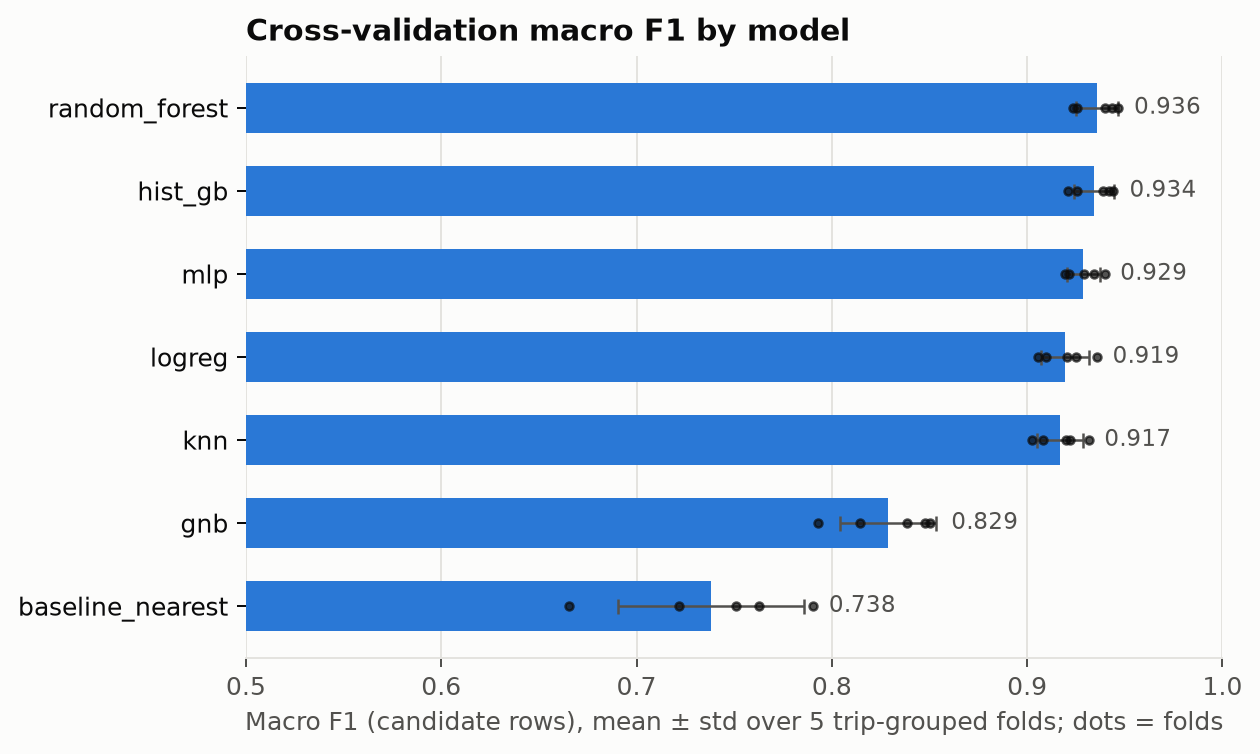

In [7]:
plots.cv_f1(cmp, fold_scores); show('cv_macro_f1.png')

**Student-test Top-1 accuracy and macro F1.** Top-1 is the selection metric: map-matching uses the ranking of candidates, not a 0.5 cut-off.

wrote results\figures\student_test_top1_f1.png


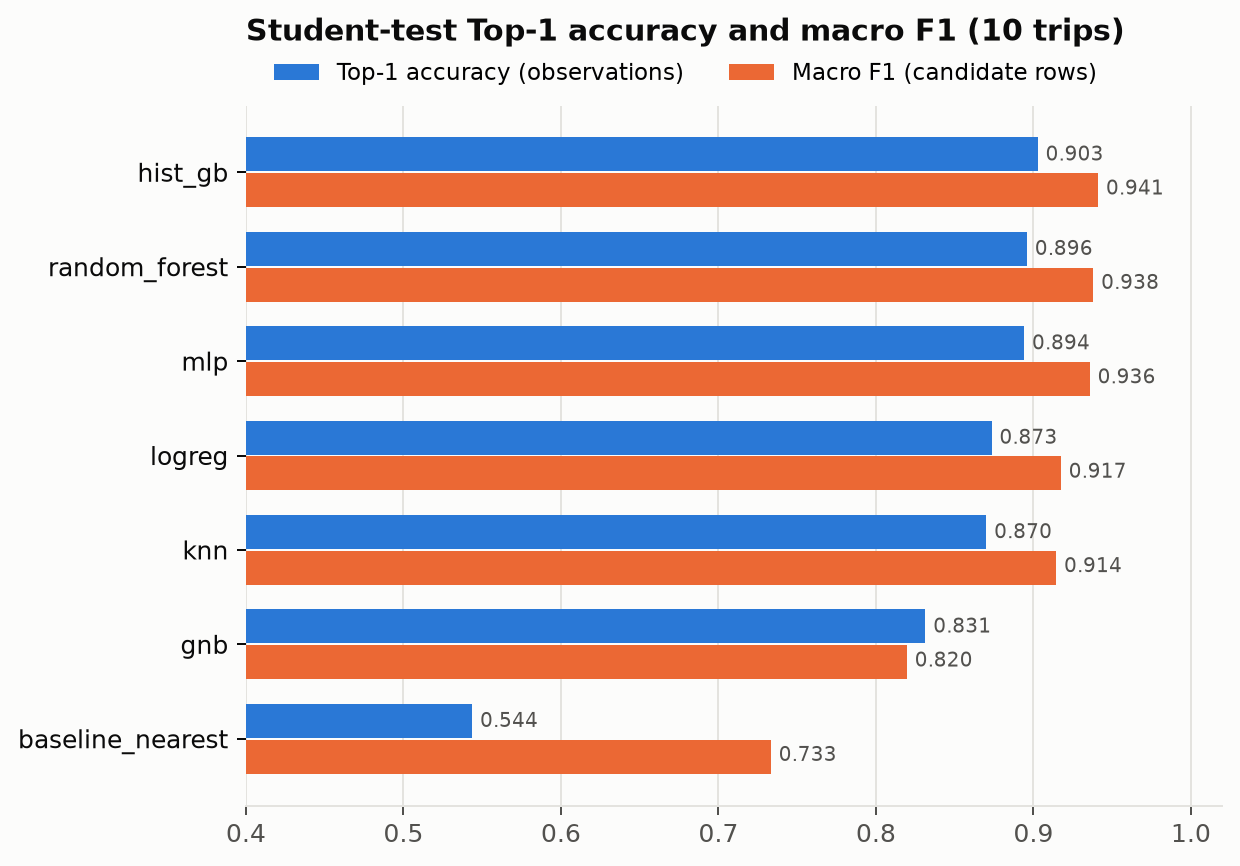

In [8]:
plots.student_test(cmp); show('student_test_top1_f1.png')

**Log loss.** Quality of the probabilities, which the HMM will use as emission scores. Lower is better.

wrote results\figures\log_loss.png


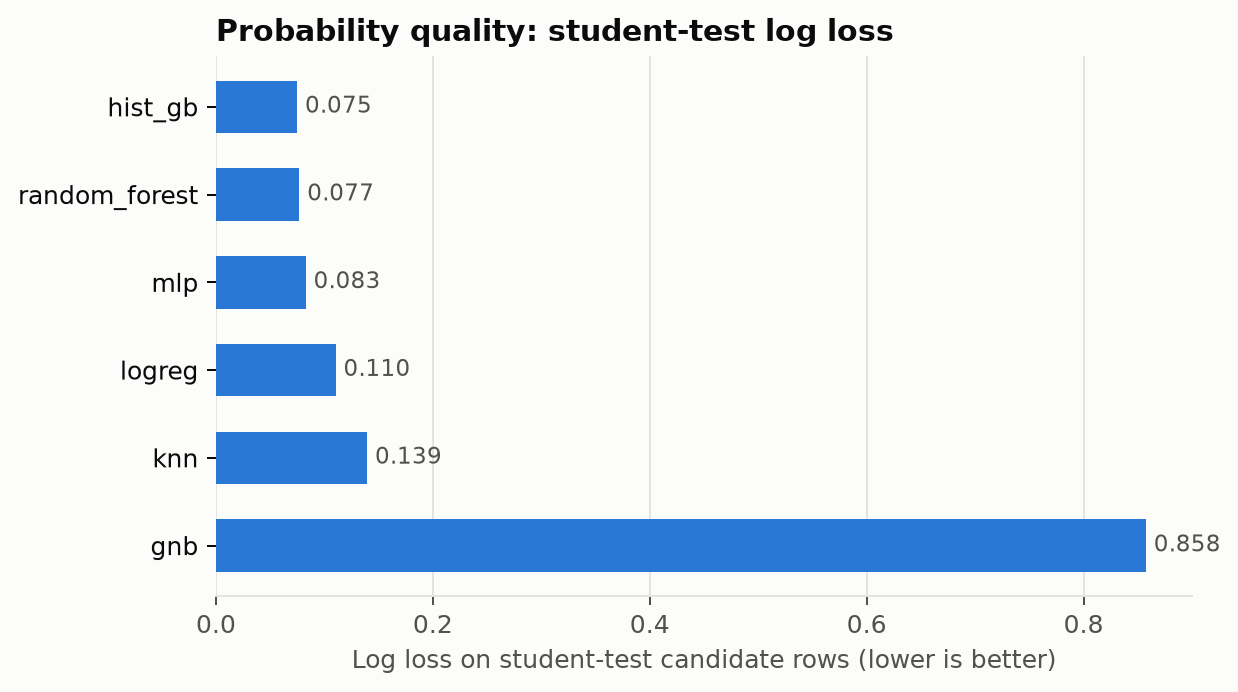

In [9]:
plots.logloss(cmp); show('log_loss.png')

**Training vs validation F1.** A large gap means overfitting (KNN memorises its training points); almost no gap with a lower score means underfitting (logistic regression).

wrote results\figures\train_vs_validation_f1.png


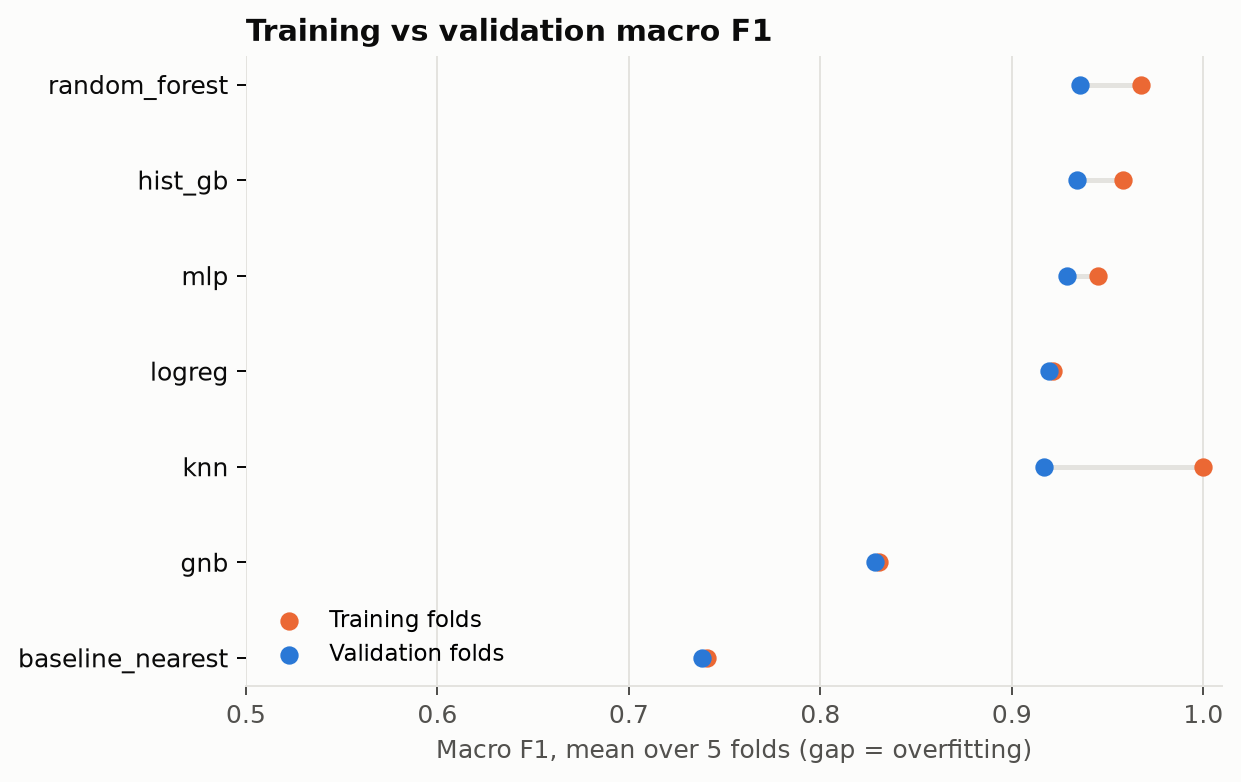

In [10]:
plots.overfit(cmp); show('train_vs_validation_f1.png')

**Inference speed.** Matters for the live API demo.

wrote results\figures\inference_time.png


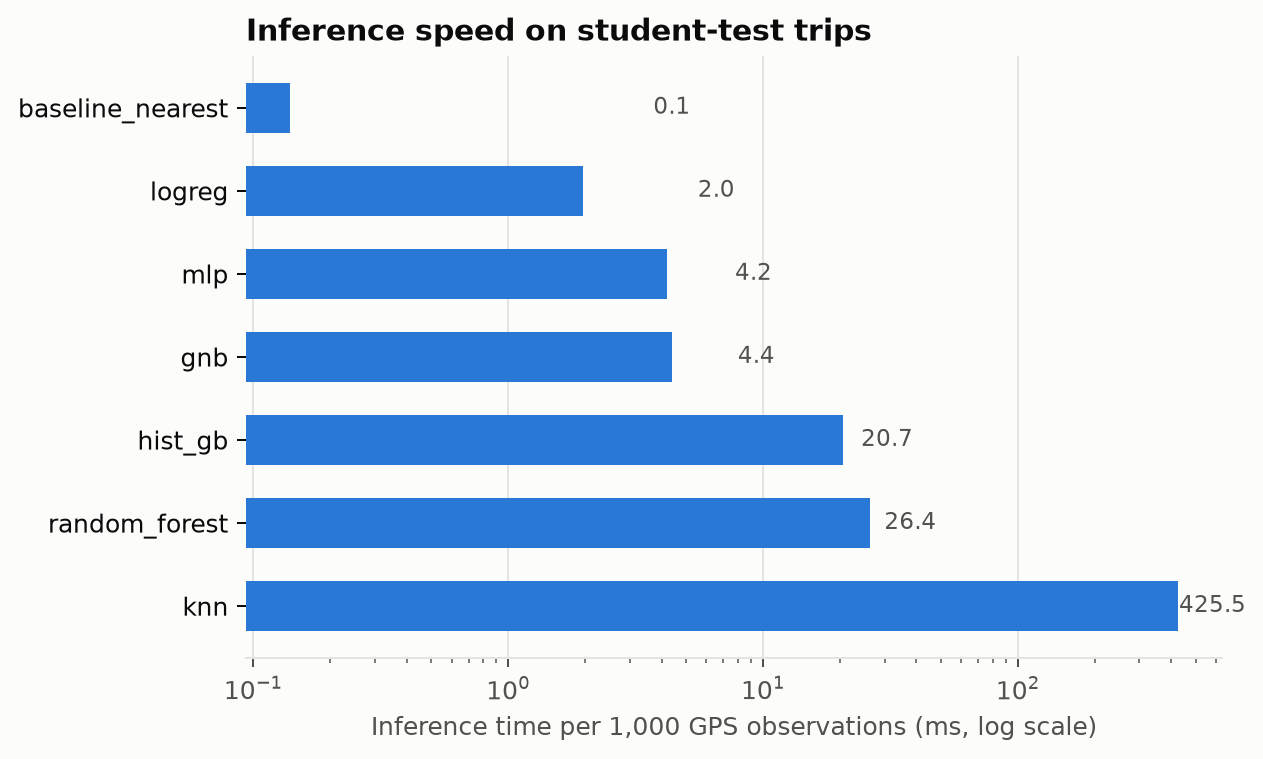

In [11]:
plots.timing(cmp); show('inference_time.png')

**Confusion matrices** on student-test candidate rows (threshold 0.5).

wrote results\figures\confusion_matrices.png


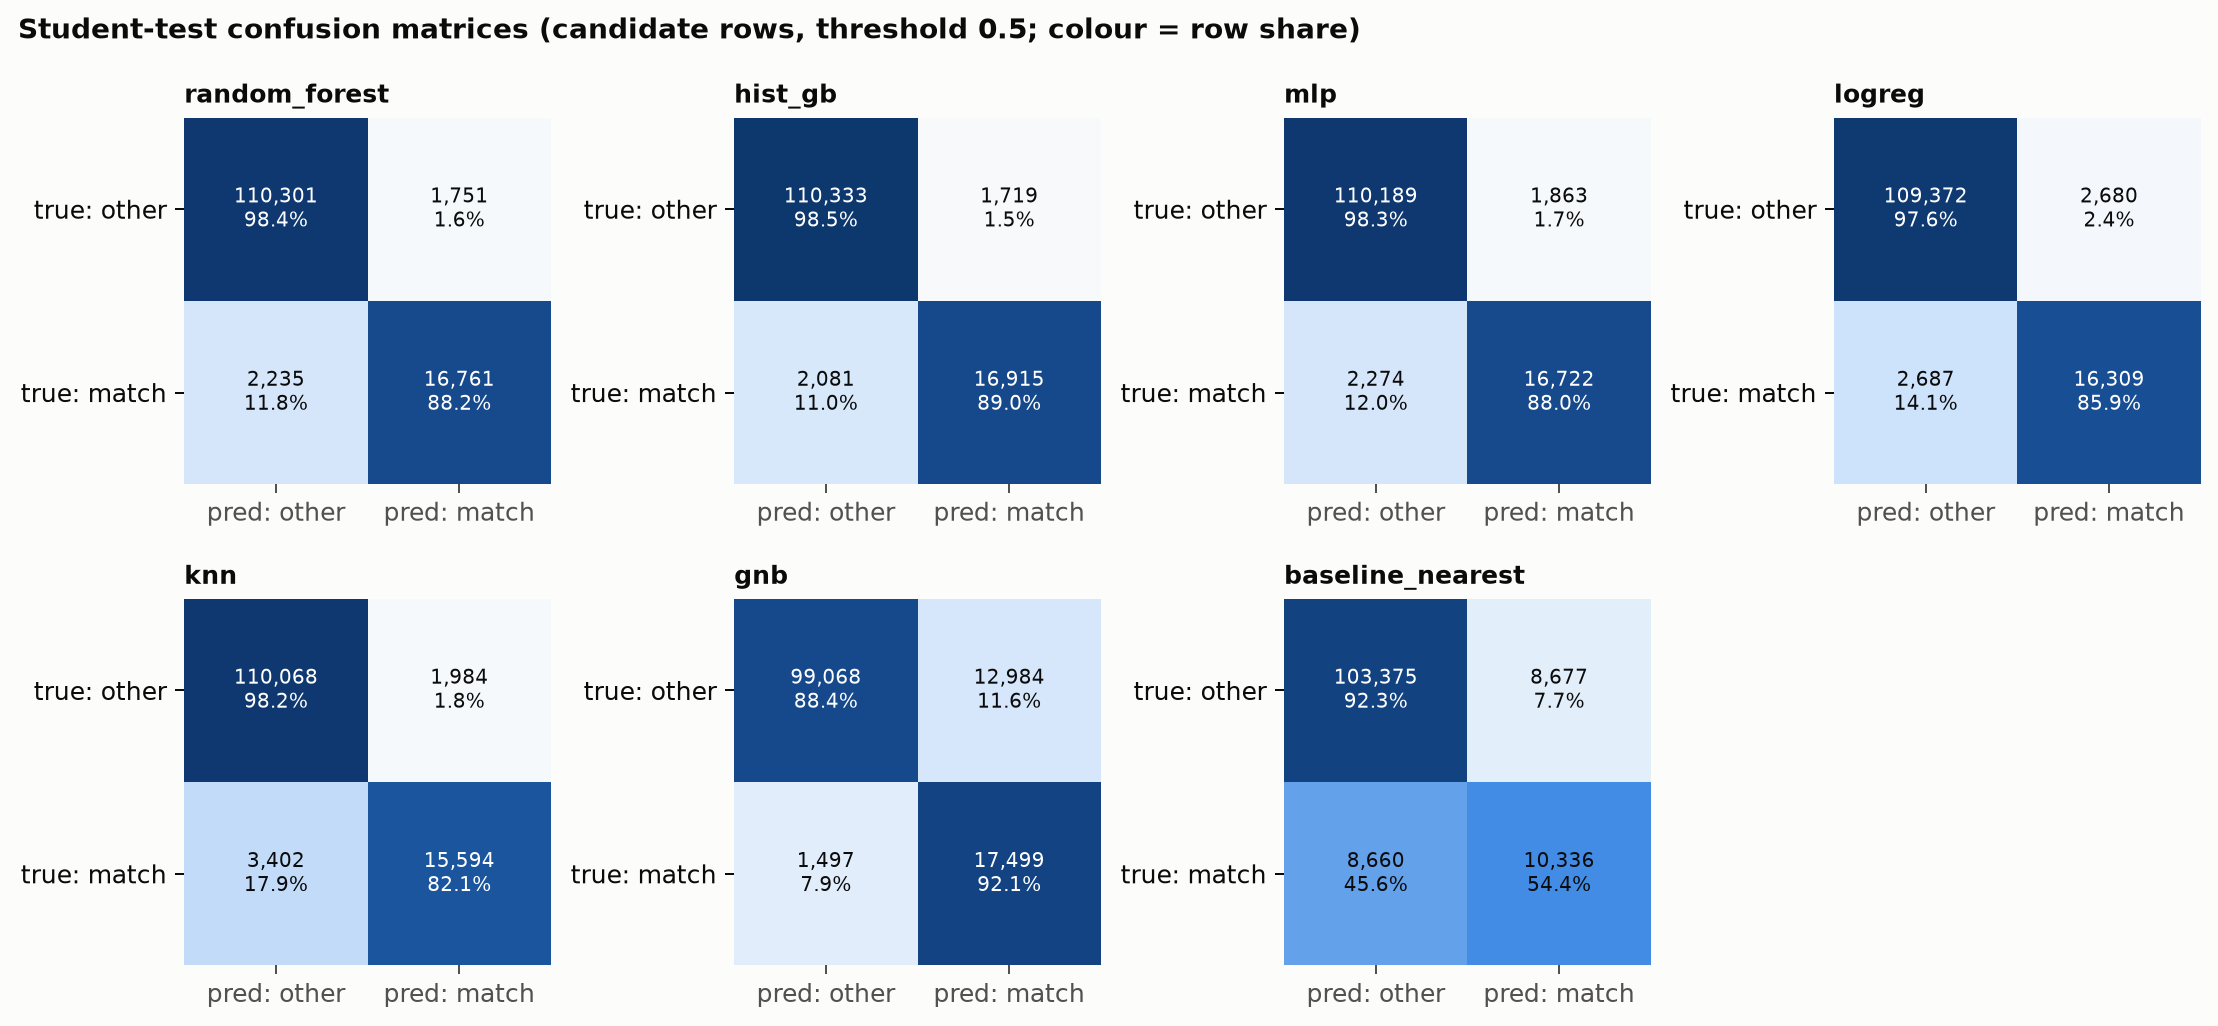

In [12]:
plots.confusions(cmp); show('confusion_matrices.png')

**Training histories**, only for models that record one per iteration or epoch (HistGradientBoosting, MLP). No curves are drawn for models without a training history.

wrote results\figures\history_hist_gb.png


wrote results\figures\history_mlp.png


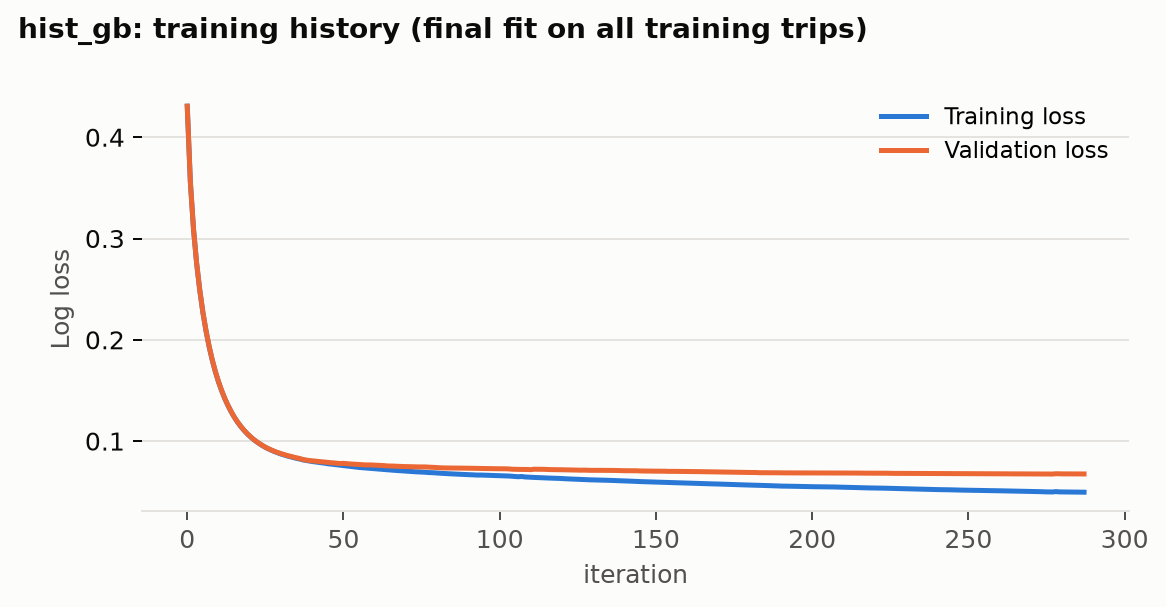

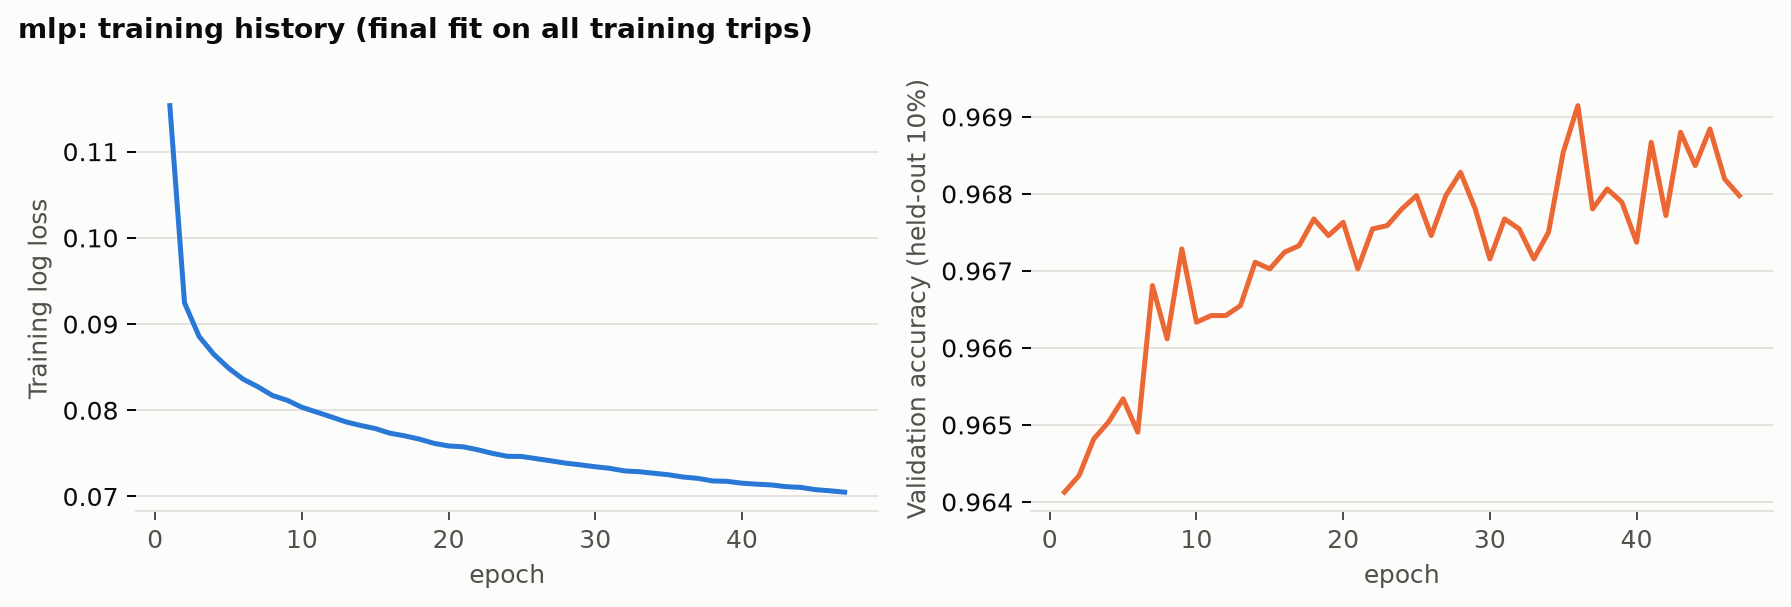

In [13]:
plots.histories(); show('history_hist_gb.png'); show('history_mlp.png')

## 6. Per-trip check: HistGradientBoosting vs random forest

The two best models are close on average; this shows the Top-1 accuracy trip by trip on the student-test set.

In [14]:
from src.eval.metrics import observation_top1
per_trip = {}
for m in ["hist_gb", "random_forest", "mlp", "logreg", "baseline_nearest"]:
    p = pd.read_parquet(f"results/preds/{m}_student_test.parquet")
    per_trip[m] = {t: observation_top1(g)["top1_acc"] for t, g in p.groupby("trip_id")}
per_trip = pd.DataFrame(per_trip)
print("HistGB beats random forest on", int((per_trip.hist_gb > per_trip.random_forest).sum()), "of", len(per_trip), "trips")
per_trip.round(3)

HistGB beats random forest on 9 of 10 trips


,hist_gb,random_forest,mlp,logreg,baseline_nearest
00000000,0.950,0.950,0.954,0.946,0.528
00000007,0.980,0.970,0.986,0.930,0.482
00000009,0.899,0.892,0.892,0.869,0.526
00000040,0.954,0.950,0.947,0.942,0.537
00000052,0.977,0.973,0.973,0.958,0.779
00000056,0.921,0.920,0.910,0.892,0.698
00000065,0.885,0.887,0.878,0.878,0.706
00000076,0.917,0.914,0.898,0.890,0.411
00000077,0.783,0.761,0.765,0.725,0.427
00000091,0.902,0.898,0.894,0.878,0.562


## 7. Map: one student-test trip

GPS points, the reference route, the best model's predicted roads and the nearest-arc baseline's picks, each as a
layer you can switch on and off. Change `TRIP` to look at another trip; `00000077` is the hardest one.

In [15]:
from src.eval.metrics import top1_choice
from src.viz.maps import trip_map

TRIP = "00000077"
obs = pd.read_parquet("data/processed/observations_student_test.parquet", filters=[("trip_id", "==", TRIP)])
arcs = pd.read_parquet("data/processed/arcs.parquet", filters=[("trip_id", "==", TRIP)]).set_index("arc_id")

def segments(arc_ids):
    seq = pd.Series(arc_ids).loc[lambda s: s != s.shift()]          # drop consecutive repeats
    a = arcs.loc[seq.to_numpy()]
    return [[[r.from_lat, r.from_lon], [r.to_lat, r.to_lon]] for r in a.itertuples()]

def predicted(model):
    p = pd.read_parquet(f"results/preds/{model}_student_test.parquet", filters=[("trip_id", "==", TRIP)])
    return segments(top1_choice(p).sort_values("obs_idx").arc_id)

m = trip_map(gps=obs[["lat", "lon"]].values.tolist(),
             reference=segments(obs.sort_values("obs_idx").ref_arc),
             predicted=predicted("hist_gb"),
             extra=[("Baseline: nearest arc", predicted("baseline_nearest"), "#eda100")])
Path("results/maps").mkdir(parents=True, exist_ok=True)
m.save(f"results/maps/trip_{TRIP}_models.html")
print(f"Saved results/maps/trip_{TRIP}_models.html  |  red = HistGB prediction, yellow = baseline, green = reference")
m

Saved results/maps/trip_00000077_models.html  |  red = HistGB prediction, yellow = baseline, green = reference
